 **A quick Introduction**

There are data scattered all around the internet.


The unique address where any of these resources are located is called the **URL (Uniform/Universal Resource Locator)**. The URLs are references to web resources.



**HTTP (HyperText Transfer Protocol)** is the base of data communication on the web. Whenever we interact with the web, we are trying to get data from it, i.e send http request.


HTTP Request (**GET request**) in plane english means getting data from the web.





# **Scrapping Reddit**

APIs(Application Programming Interface) are bunch of codes that allows two softwares to interact or communicate with each other.

For the purpose of collecting data, you can interact with standard websites using their APIs, e.g, reddits API, twitter API, etc.



**Accessing Reddits API**

In order to gain authentication for reddit API, you need to create a reddit developer app account by visiting https://www.reddit.com/prefs/apps. Then chose 'create app'(if you have not done so before', or 'create another app'(if you have created one before). This will open a form like the one below opens.

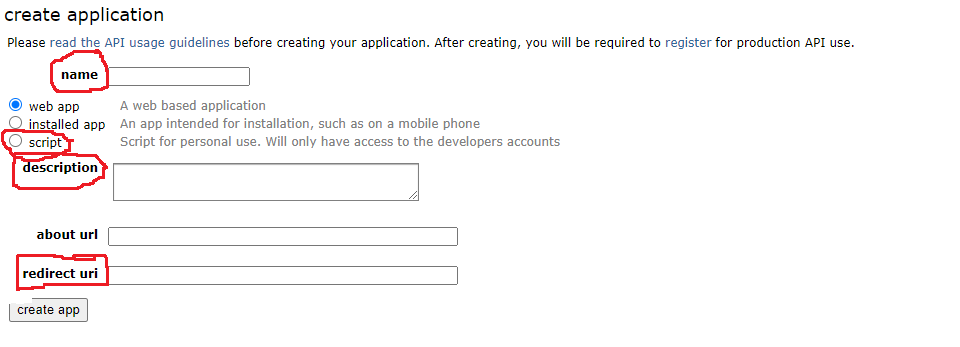

Fill out the form.

**Name** : This is the name you want the app to be called.

Click on **Script**.

**Description**. Give a short description of the app.

**redirect url**: Paste http://localhost:8080 there (don't follow the link, just copy and paste it), as described in PRAW documentation [here](https://praw.readthedocs.io/en/latest/getting_started/authentication.html#script-application).

Click on **create app**.

A new app with details like the one below will come up

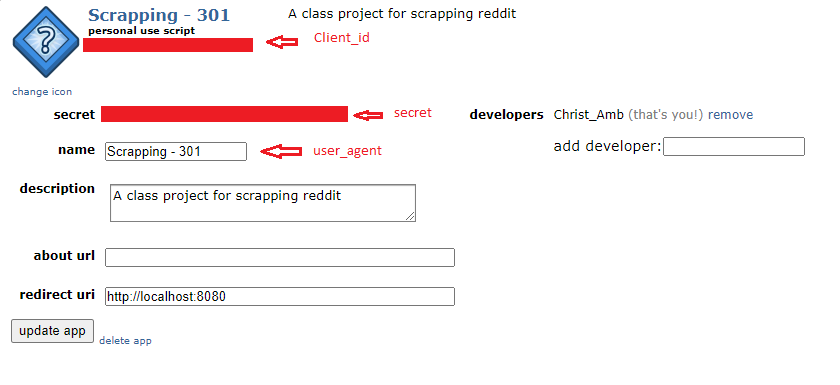

The details of this app will be used to authenticate your access to reddit using praw.

**PRAW** - Python Reddit API Wrapper. It is a python module that is used to collect data from reddit.

In [ ]:
#import libraries
!pip install praw
import requests
import pandas as pd
import praw

# **Scrapping Subreddit**

In [ ]:
# Passing your details
reddit = praw.Reddit(client_id='',
                     client_secret='',
                     user_agent='3') # Put in your credentials


In [ ]:
# Accessing the subreddit data
sl_sub_data = reddit.subreddit('StudentLoans')    # Now we have our subreddit data in the name 'sl_sub_data'
# https://www.reddit.com/r/StudentLoans/

In [ ]:
sl_sub_data

Subreddit(display_name='StudentLoans')

In [ ]:
# get 10 hot posts from the StudentLoans subreddit
hot_sl_sub_data = sl_sub_data.hot(limit=10)     # Get the top 10 hot posts from the subreddit
for post in hot_sl_sub_data:                    # Use a for loop to iterate through the post
    print(post.num_comments)                              # it will print out the objects id. We can get the title by calling .title
                                                # We can also get items such as the score, number of upvotes(ups), downvotes(downs), num_comments etc.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



578
178
107
6
0
0
0
3
2
26


In [ ]:
# In order to skip the sticky posts, we can add a code line to the previous one
hot_sl_sub_data = sl_sub_data.hot(limit=10)
for post in hot_sl_sub_data:
    if not post.stickied:                 # To skip skicky posts
        print(post.title)

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



Fairly recent major increase in income affecting daughter's FAFSA
We Applied An Administrative Forbearance to Your Account
How to best prepare: Grad School
March Forgiveness
IDRA affect PLSF?
Forgiveness - after 20 or 25 years
Nelnet inbox
MOHELA is a Joke


In [ ]:
# But we are interested in gathering more information from these posts. One important tool we will need for handling and manipulating the data is pandas
import pandas as pd

more_detail_posts = []                          # Create an empty list
hot_sl_sub_data = sl_sub_data.hot(limit=10)     # Get the top 10 hot posts
for post in hot_sl_sub_data:                    # Initiate a for-loop
    more_detail_posts.append([post.title, post.score, post.id, post.subreddit, post.url, post.num_comments, post.selftext, post.created]) # append each detail to the empty list
more_detail_posts = pd.DataFrame(more_detail_posts,columns=['title', 'score', 'id', 'subreddit', 'url', 'num_comments', 'body', 'created']) # Convert to dataframe and name the columns
print(more_detail_posts)

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



                                               title  score       id  \
0  Deadline to consolidate for the one time adjus...    257  18leqrp   
1  The /r/Studentloans Tax Questions Megathread (...     42  1ae683z   
2  Fairly recent major increase in income affecti...     47  1bon74a   
3  We Applied An Administrative Forbearance to Yo...      2  1bp0nfy   
4                   How to best prepare: Grad School      1  1bp3ouj   
5                                  March Forgiveness      1  1bp3nab   
6                                  IDRA affect PLSF?      1  1bp3lw9   
7                 Forgiveness - after 20 or 25 years      0  1bp2v7n   
8                                       Nelnet inbox      0  1bp1o3t   
9                                   MOHELA is a Joke     68  1bo8i32   

      subreddit                                                url  \
0  StudentLoans  https://www.reddit.com/r/StudentLoans/comments...   
1  StudentLoans  https://www.reddit.com/r/StudentLoans/comments... 

In [ ]:
more_detail_posts.head()

,title,score,id,subreddit,url,num_comments,body,created
0,Deadline to consolidate for the one time adjus...,257,18leqrp,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,578,To April 30 2024. https://studentaid.gov/ann...,1.702922e+09
1,The /r/Studentloans Tax Questions Megathread (...,42,1ae683z,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,178,We get a *lot* of repeat questions about how s...,1.706562e+09
2,Fairly recent major increase in income affecti...,47,1bon74a,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,107,My husband (46 M) and I (43 F) have three chil...,1.711497e+09
3,We Applied An Administrative Forbearance to Yo...,2,1bp0nfy,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,6,Did anyone else get the email that says “We're...,1.711543e+09
4,How to best prepare: Grad School,1,1bp3ouj,StudentLoans,https://www.reddit.com/r/StudentLoans/comments...,0,I want to preface this by saying the program I...,1.711551e+09


In [ ]:
more_detail_posts.shape     # Check the structure of the data

(10, 8)

In [ ]:
more_detail_posts.to_csv('our_reddit_data1.csv', index=True, header=True)

In [ ]:
# Task: Get the 40 top post in any subreddit. Only get the title, number of comments, score and date created.

# **Scrapping Multiple Subreddits**

In [ ]:
# Passing your details
reddit = praw.Reddit(client_id='',
                     client_secret='',
                     user_agent='') # Put in your credentials


In [ ]:
# Scrapping the data and convert it to dataframe

subredit_list = ["climatechange", "environment", "Environmentalism"]    # make a list of subreddits we want to scrape the data from
posts = [] # Create an empty list

for sub in subredit_list:                   # Initiate a for-loop for each of the subreddit in the subreddit_list
    sub_data = reddit.subreddit(sub)        # Save the subreddit data in an object called sub_data
    sub_hotpost = sub_data.hot(limit=20)   # Get the top 20 hot posts from each of the subreddit  # https://praw.readthedocs.io/en/v3.6.2/pages/getting_started.html#:~:text=reddit%20allows%20requests%20of%20up,to%20follow%20the%20api%20guidelines.
    for post in sub_hotpost:                # Another for-loop for each post in the sub_hot post
      posts.append([post.title, post.score, post.id, post.subreddit, post.url, post.num_comments, post.selftext, post.created])     # Append the element of each post to the empty list

posts = pd.DataFrame(posts,columns=['title', 'score', 'id', 'subreddit', 'url', 'num_comments', 'body', 'created'])                 # Convert the data to dataframe
print(posts.shape)
posts.head()

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.

It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



(60, 8)


,title,score,id,subreddit,url,num_comments,body,created
0,I'm afraid climate change is going to kill me!...,739,aqdmbz,climatechange,https://www.reddit.com/r/climatechange/comment...,638,Feeling scared? Have you been listening to or ...,1.550104e+09
1,The r/climatechange Verified User Flair Program,32,wu9zny,climatechange,https://www.reddit.com/r/climatechange/comment...,17,r/climatechange is a community centered around...,1.661115e+09
2,This Map Shows Where Planting Trees Would Make...,5,1bp254c,climatechange,https://e360.yale.edu/digest/tree-planting-cli...,3,,1.711547e+09
3,Is this a thing?,26,1boqg1v,climatechange,https://www.reddit.com/r/climatechange/comment...,34,So before I get made fun of I'm just a stay at...,1.711505e+09
4,No gas cars in New York after 2035.,100,1bofpdj,climatechange,https://www.reddit.com/r/climatechange/comment...,114,How is that going to work in the NY mountains....,1.711479e+09


In [ ]:
# Getting the elements of a row (post)
posts.iloc[56]

title           We help companies reduce carbon emissions, and...
score                                                           0
id                                                        1bilw6b
subreddit                                        Environmentalism
url             https://www.reddit.com/r/Environmentalism/comm...
num_comments                                                    0
body            Hey community,\n\nAs fellow climate enthusiast...
created                                              1710859320.0
Name: 56, dtype: object

In [ ]:
# Getting the elements of a particular cell
posts.iloc[4]['url']

'https://www.reddit.com/r/climatechange/comments/1bofpdj/no_gas_cars_in_new_york_after_2035/'

In [ ]:
# Converting the created date to what we can easily read

from datetime import datetime

posts['date_time'] = pd.to_datetime(posts['created'],  unit='s')    # this passes all the time details, including time. # The unit specify what unit our int is is away from the origin (January 1, 1970)
posts['date'] = posts['date_time'].dt.strftime('%Y-%m-%d') # Now we have created a formatted string, with only the date

posts.head()

,title,score,id,subreddit,url,num_comments,body,created,date_time,date
0,I'm afraid climate change is going to kill me!...,739,aqdmbz,climatechange,https://www.reddit.com/r/climatechange/comment...,638,Feeling scared? Have you been listening to or ...,1.550104e+09,2019-02-14 00:22:32,2019-02-14
1,The r/climatechange Verified User Flair Program,32,wu9zny,climatechange,https://www.reddit.com/r/climatechange/comment...,17,r/climatechange is a community centered around...,1.661115e+09,2022-08-21 20:53:23,2022-08-21
2,This Map Shows Where Planting Trees Would Make...,5,1bp254c,climatechange,https://e360.yale.edu/digest/tree-planting-cli...,3,,1.711547e+09,2024-03-27 13:40:50,2024-03-27
3,Is this a thing?,26,1boqg1v,climatechange,https://www.reddit.com/r/climatechange/comment...,34,So before I get made fun of I'm just a stay at...,1.711505e+09,2024-03-27 02:08:39,2024-03-27
4,No gas cars in New York after 2035.,100,1bofpdj,climatechange,https://www.reddit.com/r/climatechange/comment...,114,How is that going to work in the NY mountains....,1.711479e+09,2024-03-26 18:51:55,2024-03-26


In [ ]:
posts.shape

(60, 10)

In [ ]:
# Remove the duplicate and save data to csv file
posts1 = posts
posts1.drop_duplicates(subset='title', keep='last', inplace=True)
posts1.to_csv('multireddit_data.csv', index=True, header=True)
posts1.shape #view dimension of data to see how many data points remain after cleaning


(60, 10)

# **Word-based search in Reddit**

In [ ]:
# Passing your details
reddit = praw.Reddit(client_id='',
                     client_secret='',
                     user_agent='') # Put in your credentials


In [ ]:
# search parameters
word ='CO2'
sub_list = 'climatechange+climate+environment+environmentalism'

sort = "hot"
limit = 100

# Create a search to the subreddit.
top_posts = reddit.subreddit(sub_list).search(word, sort=sort, limit=limit)

# Initialize an empty list
total_posts = list()

# Iterate over the top_posts
for post in top_posts:
    # print('type', vars(post)) # print all properties
    title=post.title,
    score = post.score,
    number_of_comments = post.num_comments,
    posted_date = post.created,
    link = post.permalink,
    data_set = {"title":title[0],"score":score[0], "number_of_comments":number_of_comments[0],"posted_date":posted_date[0],"link":'https://www.reddit.com'+link[0]}
    total_posts.append(data_set)  # append the newly created dictionary into total_posts.

# create csv file
reddit_co2_data = pd.DataFrame(total_posts)
print(reddit_co2_data.shape)


It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



(100, 5)


In [ ]:
reddit_co2_data.head()

,title,score,number_of_comments,posted_date,link
0,CO2 jumped by record amount last year - “The a...,89,7,1.711541e+09,https://www.reddit.com/r/climate/comments/1bp0...
1,"Portugal reducing CO2 emissions by 170,000 ton...",67,23,1.711340e+09,https://www.reddit.com/r/climatechange/comment...
2,"Carbon Brief report — In the 1750-2023 period,...",12,0,1.711370e+09,https://www.reddit.com/r/climatechange/comment...
3,2023: RECORD CO2 + Heat: What's next? - doing ...,25,13,1.711312e+09,https://www.reddit.com/r/climate/comments/1bmu...
4,How much do Urban Heat Islands impact global c...,12,9,1.711416e+09,https://www.reddit.com/r/climatechange/comment...


In [ ]:
reddit_co2_data.iloc[0]['title']

'CO2 jumped by record amount last year - “The accumulation of CO2 in the atmosphere is irreversible on human timescales and will affect climate for millennia.”'

In [ ]:
# Converting the created date to what we can easily read

from datetime import datetime

reddit_co2_data['date_time'] = pd.to_datetime(reddit_co2_data['posted_date'],  unit='s')    # this passes all the time details, including time. # The unit specify what unit our int is is away from the origin
reddit_co2_data['date'] = reddit_co2_data['date_time'].dt.strftime('%Y-%m-%d') # Now we have created a formatted string, with only the date

reddit_co2_data.head()

,title,score,number_of_comments,posted_date,link,date_time,date
0,CO2 jumped by record amount last year - “The a...,89,7,1.711541e+09,https://www.reddit.com/r/climate/comments/1bp0...,2024-03-27 12:01:30,2024-03-27
1,"Portugal reducing CO2 emissions by 170,000 ton...",67,23,1.711340e+09,https://www.reddit.com/r/climatechange/comment...,2024-03-25 04:11:48,2024-03-25
2,"Carbon Brief report — In the 1750-2023 period,...",12,0,1.711370e+09,https://www.reddit.com/r/climatechange/comment...,2024-03-25 12:35:34,2024-03-25
3,2023: RECORD CO2 + Heat: What's next? - doing ...,25,13,1.711312e+09,https://www.reddit.com/r/climate/comments/1bmu...,2024-03-24 20:23:11,2024-03-24
4,How much do Urban Heat Islands impact global c...,12,9,1.711416e+09,https://www.reddit.com/r/climatechange/comment...,2024-03-26 01:13:34,2024-03-26


In [ ]:
#save data to csv file
reddit_co2_data1 = reddit_co2_data
reddit_co2_data1.drop_duplicates(subset='title', keep='last', inplace=True)
reddit_co2_data1.to_csv('reddit_data1.csv', index=True, header=True)
reddit_co2_data1.shape #view dimension of data to see how many data points remain after cleaning


(98, 7)

# **Scrapping Reddit Comments**

In this section, we will be scrapping the comments from a particular reddit post.

In [ ]:
# Passing your details
sl_comments = praw.Reddit(client_id='',
                     client_secret='',
                     user_agent='') # Put in your credentials


In [ ]:
# URL of the post
url = "https://www.reddit.com/r/FluentInFinance/comments/16gegy0/would_you_forgive_student_loan_debt_if_you_were/"

# Creating a submission object
submission = sl_comments.submission(url=url)


In [ ]:
# Checking out the content/properties of the post
submission.id       # You can also pass .title etc.

# But for .comments, what you will have is a comment_forest

'16gegy0'

In [ ]:
from praw.models import MoreComments			# Importing needed function from praw package

post_comments = []												# Create an empty list

for comment in submission.comments:				# Initiate a for loop through the comment forest
	if type(comment) == MoreComments:				# This helps to handle objects that has “load more comments” and “continue this thread”.
		continue

	post_comments.append(comment.body)			# Append the comment body to the empty list

# creating a dataframe
comments_df = pd.DataFrame(post_comments, columns=['comment'])		# Convert the 'post_comments' list to dataframe and naming the column.
comments_df


It is strongly recommended to use Async PRAW: https://asyncpraw.readthedocs.io.
See https://praw.readthedocs.io/en/latest/getting_started/multiple_instances.html#discord-bots-and-asynchronous-environments for more info.



,comment
0,r/FluentInFinance was created to discuss money...
1,[removed]
2,No. quit positing this trash
3,This sub fucking sucks from these comments
4,"No, but I’d crack down on these college racket..."
...,...
120,Saw way too many people failing classes becaus...
121,Fuck yes. And then make all student loans inte...
122,Yes
123,Yes. And I’d make college free. Not out of the...


In [ ]:
comments_df.shape

(125, 1)

In [ ]:
# Including all the comments within comments
post_comments = []  # Create an empty list


submission.comments.replace_more(limit=None)
for comment in submission.comments.list():
 post_comments.append([comment.body, comment.ups, comment.downs, comment.created]) # Append the comment body to the empty list

# creating a dataframe
# Convert the 'post_comments' list to dataframe and naming the column.
comments_df = pd.DataFrame(post_comments, columns=['comment', 'ups', 'downs', 'created'])
comments_df

In [ ]:
comments_df.shape

(2621, 4)

In [ ]:
# Converting the created date to what we can easily read

from datetime import datetime

comments_df['date_time'] = pd.to_datetime(comments_df['created'],  unit='s')    # this passes all the time details, including time. # The unit specify what unit our int is is away from the origin
comments_df['date'] = comments_df['date_time'].dt.strftime('%Y-%m-%d') # Now we have created a formatted string, with only the date

comments_df.head()

,comment,ups,downs,created,date_time,date
0,r/FluentInFinance was created to discuss money...,1,0,1.694484e+09,2023-09-12 01:56:42,2023-09-12
1,[removed],585,0,1.694489e+09,2023-09-12 03:15:30,2023-09-12
2,No. quit positing this trash,5,0,1.694537e+09,2023-09-12 16:47:28,2023-09-12
3,This sub fucking sucks from these comments,129,0,1.694497e+09,2023-09-12 05:41:05,2023-09-12
4,"No, but I’d crack down on these college racket...",19,0,1.694501e+09,2023-09-12 06:43:15,2023-09-12


In [ ]:
# Counting characters in the 'text_column'
comments_df['character_count'] = comments_df['comment'].apply(lambda x: len(x))
comments_df

,comment,ups,downs,created,date_time,date,character_count
0,r/FluentInFinance was created to discuss money...,1,0,1.694484e+09,2023-09-12 01:56:42,2023-09-12,359
1,[removed],585,0,1.694489e+09,2023-09-12 03:15:30,2023-09-12,9
2,No. quit positing this trash,5,0,1.694537e+09,2023-09-12 16:47:28,2023-09-12,28
3,This sub fucking sucks from these comments,129,0,1.694497e+09,2023-09-12 05:41:05,2023-09-12,42
4,"No, but I’d crack down on these college racket...",19,0,1.694501e+09,2023-09-12 06:43:15,2023-09-12,139
...,...,...,...,...,...,...,...
2616,If it was you wouldn’t be crying about how hel...,1,0,1.694655e+09,2023-09-14 01:23:35,2023-09-14,74
2617,"Help isn’t coming, we agreed on that.\n\nWe di...",1,0,1.694655e+09,2023-09-14 01:31:41,2023-09-14,258
2618,The part where you get to pay for your own loa...,1,0,1.694655e+09,2023-09-14 01:34:54,2023-09-14,193
2619,You’re not even replying to the words I’m sayi...,0,0,1.694656e+09,2023-09-14 01:41:55,2023-09-14,538


In [ ]:
# Counting words in the 'text_column'
comments_df['word_count'] = comments_df['comment'].apply(lambda x: len(x.split()))
comments_df

,comment,ups,downs,created,date_time,date,character_count,word_count
0,r/FluentInFinance was created to discuss money...,1,0,1.694484e+09,2023-09-12 01:56:42,2023-09-12,359,44
1,[removed],585,0,1.694489e+09,2023-09-12 03:15:30,2023-09-12,9,1
2,No. quit positing this trash,5,0,1.694537e+09,2023-09-12 16:47:28,2023-09-12,28,5
3,This sub fucking sucks from these comments,129,0,1.694497e+09,2023-09-12 05:41:05,2023-09-12,42,7
4,"No, but I’d crack down on these college racket...",19,0,1.694501e+09,2023-09-12 06:43:15,2023-09-12,139,25
...,...,...,...,...,...,...,...,...
2616,If it was you wouldn’t be crying about how hel...,1,0,1.694655e+09,2023-09-14 01:23:35,2023-09-14,74,14
2617,"Help isn’t coming, we agreed on that.\n\nWe di...",1,0,1.694655e+09,2023-09-14 01:31:41,2023-09-14,258,45
2618,The part where you get to pay for your own loa...,1,0,1.694655e+09,2023-09-14 01:34:54,2023-09-14,193,37
2619,You’re not even replying to the words I’m sayi...,0,0,1.694656e+09,2023-09-14 01:41:55,2023-09-14,538,93


In [ ]:
# Remove the duplicate and save data to csv file
comments_df1 = comments_df
comments_df1.drop_duplicates(subset='comment', keep='last', inplace=True)
comments_df1.to_csv('sl_comments.csv', index=True, header=True)
comments_df1.shape #view dimension of data to see how many data points remain after cleaning


(2518, 8)